# Evaluación Parcial N.º 1 — Fundamentos de Deep Learning (DLY0100)

**Integrantes:**
1. Jaime Alvarez

## Clasificación multietiqueta con una red neuronal MLP

**Objetivo.** Construir y evaluar una red neuronal que prediga simultáneamente tres intereses: tecnología, moda y deportes. Cada salida es binaria, por lo que una persona puede tener cero, uno o varios intereses.

**Variables objetivo:** `interes_tecnologia`, `interes_moda` e `interes_deportes`.




## 1. Librerías y reproducibilidad

Se utilizan pandas y NumPy para manipulación de datos, Matplotlib/Seaborn para gráficos, scikit-learn para partición y métricas, y TensorFlow/Keras para construir la MLP. Se fija una semilla para facilitar la reproducibilidad; aun así, el resultado puede variar entre equipos o versiones de las librerías.

In [28]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.metrics import Precision, Recall

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score,
    precision_recall_fscore_support, hamming_loss
)

SEED = 1102
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Librerías importadas correctamente.")


Librerías importadas correctamente.


## 2. Carga y exploración de los datos

Primero se revisan las dimensiones, tipos de datos, estadísticas descriptivas, valores faltantes y distribuciones. Esta etapa permite detectar problemas antes del entrenamiento.

In [29]:
df=pd.read_csv('dataset.csv')
df.head(5)

,edad,tiempo_sesion,paginas_vistas,historial_compras,descuentos_usados,dispositivo_movil,valoracion_media,frecuencia_devolucion,clics_publicidad,interaccion_redes,interes_tecnologia,interes_moda,interes_deportes
0,0.473008,-2.015216,-0.617204,1.912964,1.104647,7.124469,-2.477666,-0.135015,-0.542116,-0.761970,0,1,1
1,0.578279,0.967299,1.443789,0.993972,-0.620909,-0.667771,-1.835993,-4.181187,1.502827,-1.455356,1,0,0
2,0.101556,-0.773922,-0.164761,0.464491,2.402765,-1.150528,0.157838,0.322459,-0.268127,0.219723,1,0,1
3,-0.091381,-1.361323,2.749614,-1.941579,-0.092780,-3.207476,-1.517199,1.829656,0.880481,-0.589325,0,1,0
4,1.953657,1.248484,1.212312,0.515772,-0.559830,-0.907930,113.927263,1.052013,0.281696,NaN,1,0,1


In [30]:
# 1. Exploración inicial
print(f"Dimensiones: {df.shape}\n")
display(df.info())
display(df.describe())

Dimensiones: (2660, 13)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2660 entries, 0 to 2659
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   edad                   2527 non-null   float64
 1   tiempo_sesion          2527 non-null   float64
 2   paginas_vistas         2527 non-null   float64
 3   historial_compras      2527 non-null   float64
 4   descuentos_usados      2527 non-null   float64
 5   dispositivo_movil      2527 non-null   float64
 6   valoracion_media       2527 non-null   float64
 7   frecuencia_devolucion  2527 non-null   float64
 8   clics_publicidad       2527 non-null   float64
 9   interaccion_redes      2527 non-null   float64
 10  interes_tecnologia     2660 non-null   int64  
 11  interes_moda           2660 non-null   int64  
 12  interes_deportes       2660 non-null   int64  
dtypes: float64(10), int64(3)
memory usage: 270.3 KB


None

,edad,tiempo_sesion,paginas_vistas,historial_compras,descuentos_usados,dispositivo_movil,valoracion_media,frecuencia_devolucion,clics_publicidad,interaccion_redes,interes_tecnologia,interes_moda,interes_deportes
count,2527.000000,2527.000000,2527.000000,2527.000000,2527.000000,2527.000000,2527.000000,2527.000000,2527.000000,2527.000000,2660.000000,2660.000000,2660.000000
mean,0.028644,-0.509256,-0.669196,-0.071617,-1.495201,-0.962142,0.496815,0.462469,-0.010479,0.316455,0.434586,0.437218,0.433459
std,2.864742,11.663665,25.176848,9.287414,45.253356,3.577355,17.082451,4.881745,1.195890,11.503382,0.495796,0.496136,0.495646
min,-98.148405,-407.855167,-880.978886,-167.607977,-1584.224648,-89.608936,-221.057319,-121.327790,-9.717513,-429.825192,0.000000,0.000000,0.000000
25%,-0.705508,-1.254657,-1.198387,-2.385029,-1.734092,-1.871420,-1.193552,-0.645409,-0.692452,-0.716109,0.000000,0.000000,0.000000
50%,-0.001330,-0.057786,0.073469,-0.081522,-0.646663,-0.981453,-0.111521,0.552520,-0.006665,0.341631,0.000000,0.000000,0.000000
75%,0.732280,0.978884,1.302754,1.467249,0.438737,-0.118926,1.091570,1.632515,0.641638,1.488356,1.000000,1.000000,1.000000
max,70.526039,108.165792,325.953770,324.435524,1135.567267,122.427075,597.603451,170.020681,11.623093,309.445769,1.000000,1.000000,1.000000


--- Resumen de Valores Faltantes ---


,Valores faltantes,Porcentaje (%)
edad,133,5.0
tiempo_sesion,133,5.0
paginas_vistas,133,5.0
historial_compras,133,5.0
descuentos_usados,133,5.0
dispositivo_movil,133,5.0
valoracion_media,133,5.0
frecuencia_devolucion,133,5.0
clics_publicidad,133,5.0
interaccion_redes,133,5.0


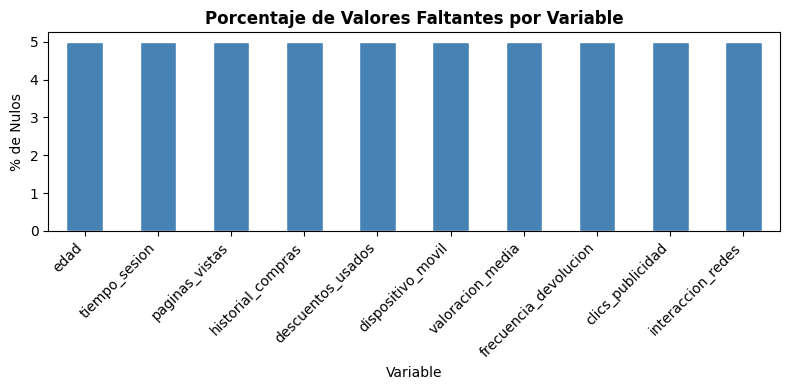

In [31]:
# 2. Resumen de faltantes (Tabla con Cantidad y %)
missing = pd.DataFrame({
    'Valores faltantes': df.isnull().sum(),
    'Porcentaje (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
missing = missing[missing['Valores faltantes'] > 0].sort_values('Porcentaje (%)', ascending=False)

print("--- Resumen de Valores Faltantes ---")
display(missing)

# 3. Un solo gráfico de nulos
if not missing.empty:
    plt.figure(figsize=(8, 4))
    ax = missing['Porcentaje (%)'].plot(kind='bar', color='steelblue', edgecolor='white')
    plt.title('Porcentaje de Valores Faltantes por Variable', fontsize=12, fontweight='bold')
    plt.ylabel('% de Nulos')
    plt.xlabel('Variable')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron valores nulos en el dataset.")

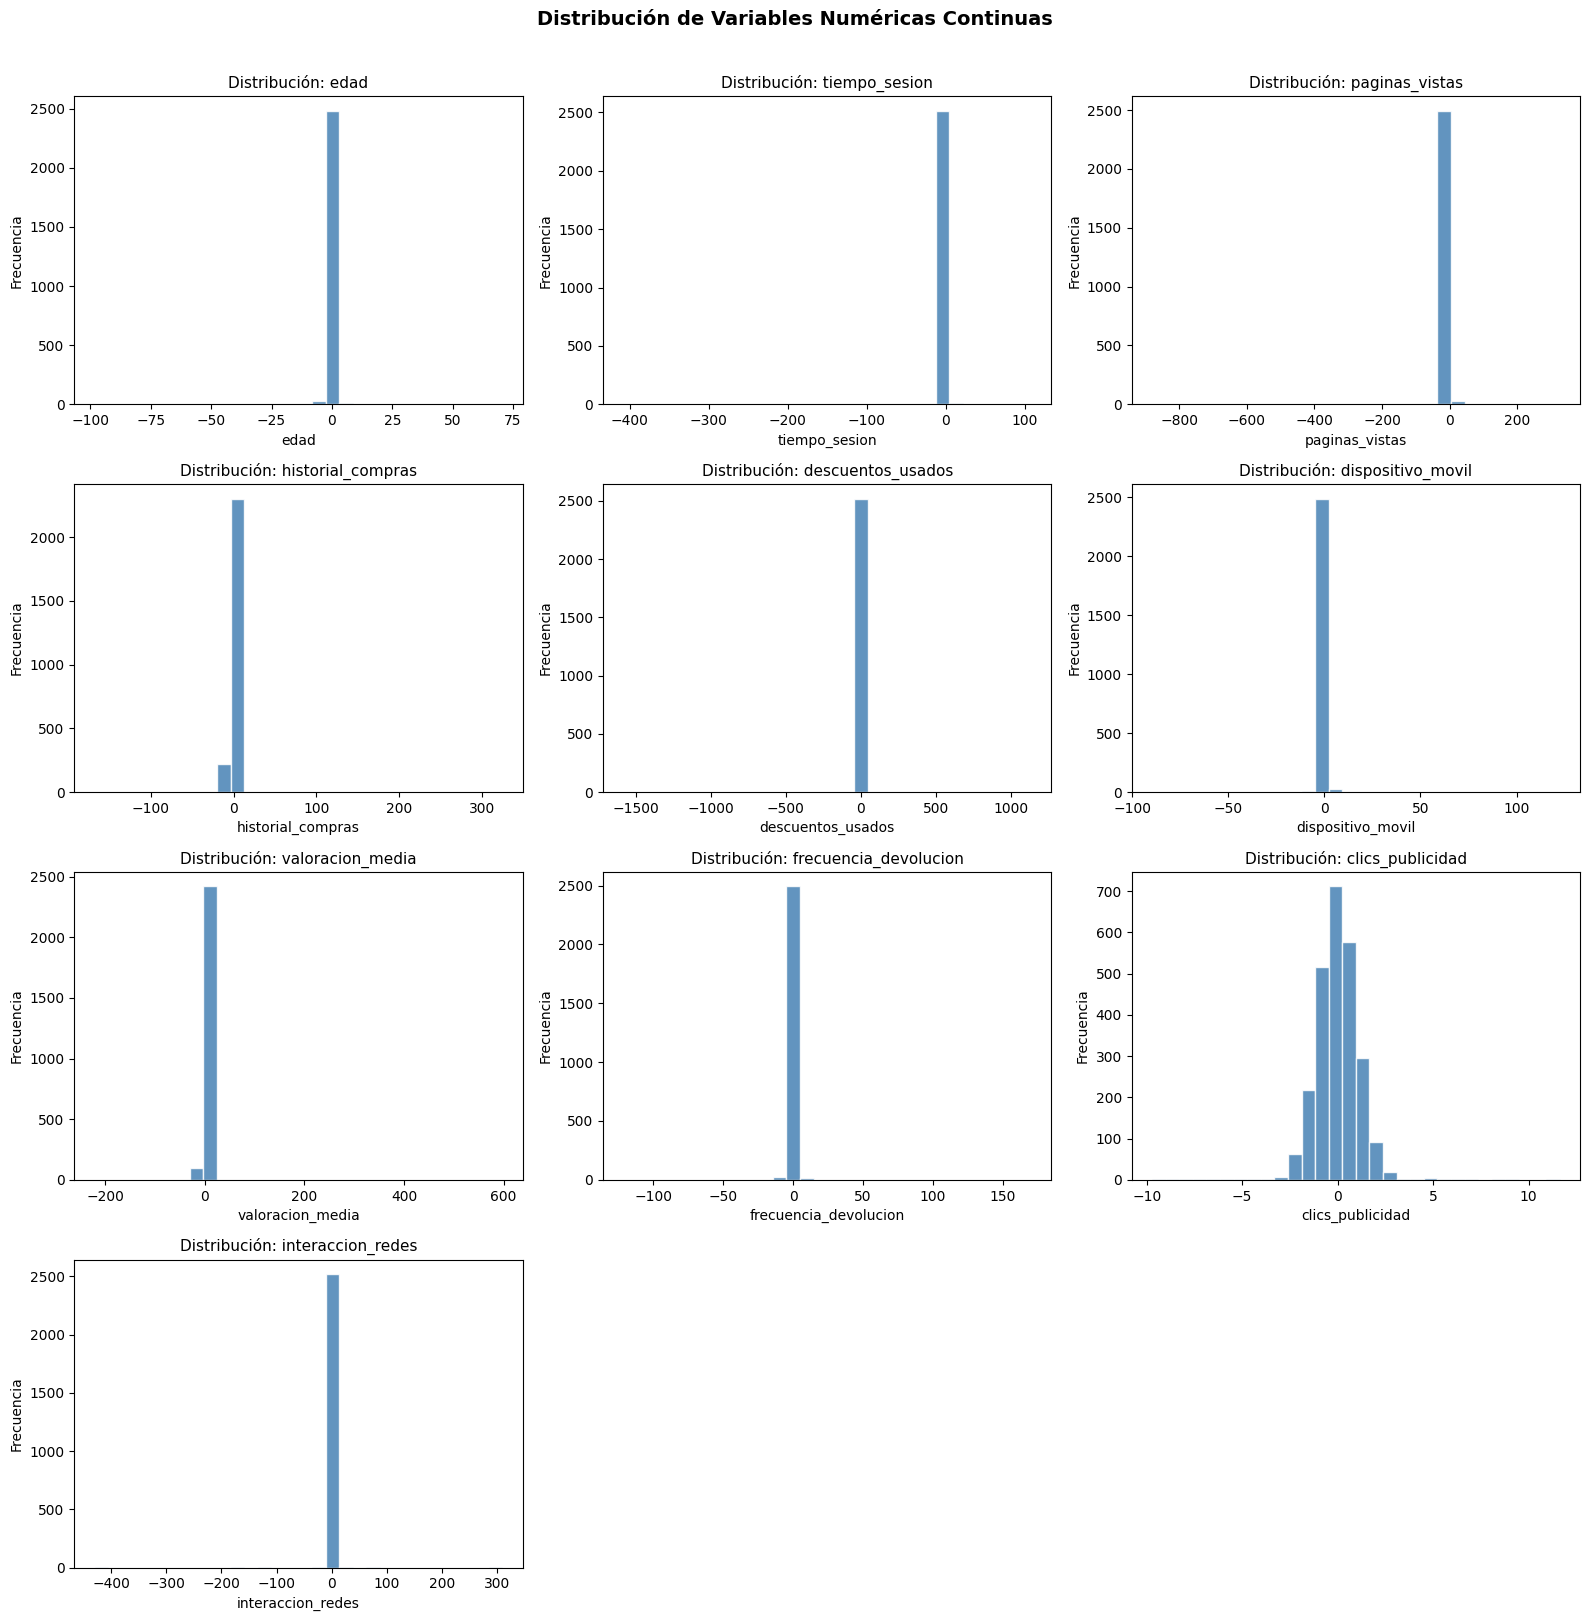

In [33]:
# Distribución de todas las variables numéricas
numericas = df.select_dtypes(include=[np.number]).columns.tolist()

# Excluimos variables binarias/indicadoras de tu dataset
columnas_binarias = ['interes_tecnologia', 'interes_moda', 'interes_deportes']
numericas_plot = [c for c in numericas if c not in columnas_binarias]

# Calcular automáticamente el número de subgráficos
n = len(numericas_plot)
ncols = 3
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(16, 4 * nrows),
    squeeze=False
)

axes = axes.flatten()

# Graficar las distribuciones
for i, col in enumerate(numericas_plot):
    axes[i].hist(
        df[col].dropna(),
        bins=30,
        color='steelblue',
        edgecolor='white',
        alpha=0.85
    )
    axes[i].set_title(f'Distribución: {col}', fontsize=11)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frecuencia')

# Ocultar los subgráficos sobrantes
for j in range(n, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(
    'Distribución de Variables Numéricas Continuas',
    fontsize=14,
    fontweight='bold',
    y=1.01
)

plt.tight_layout()
plt.show()

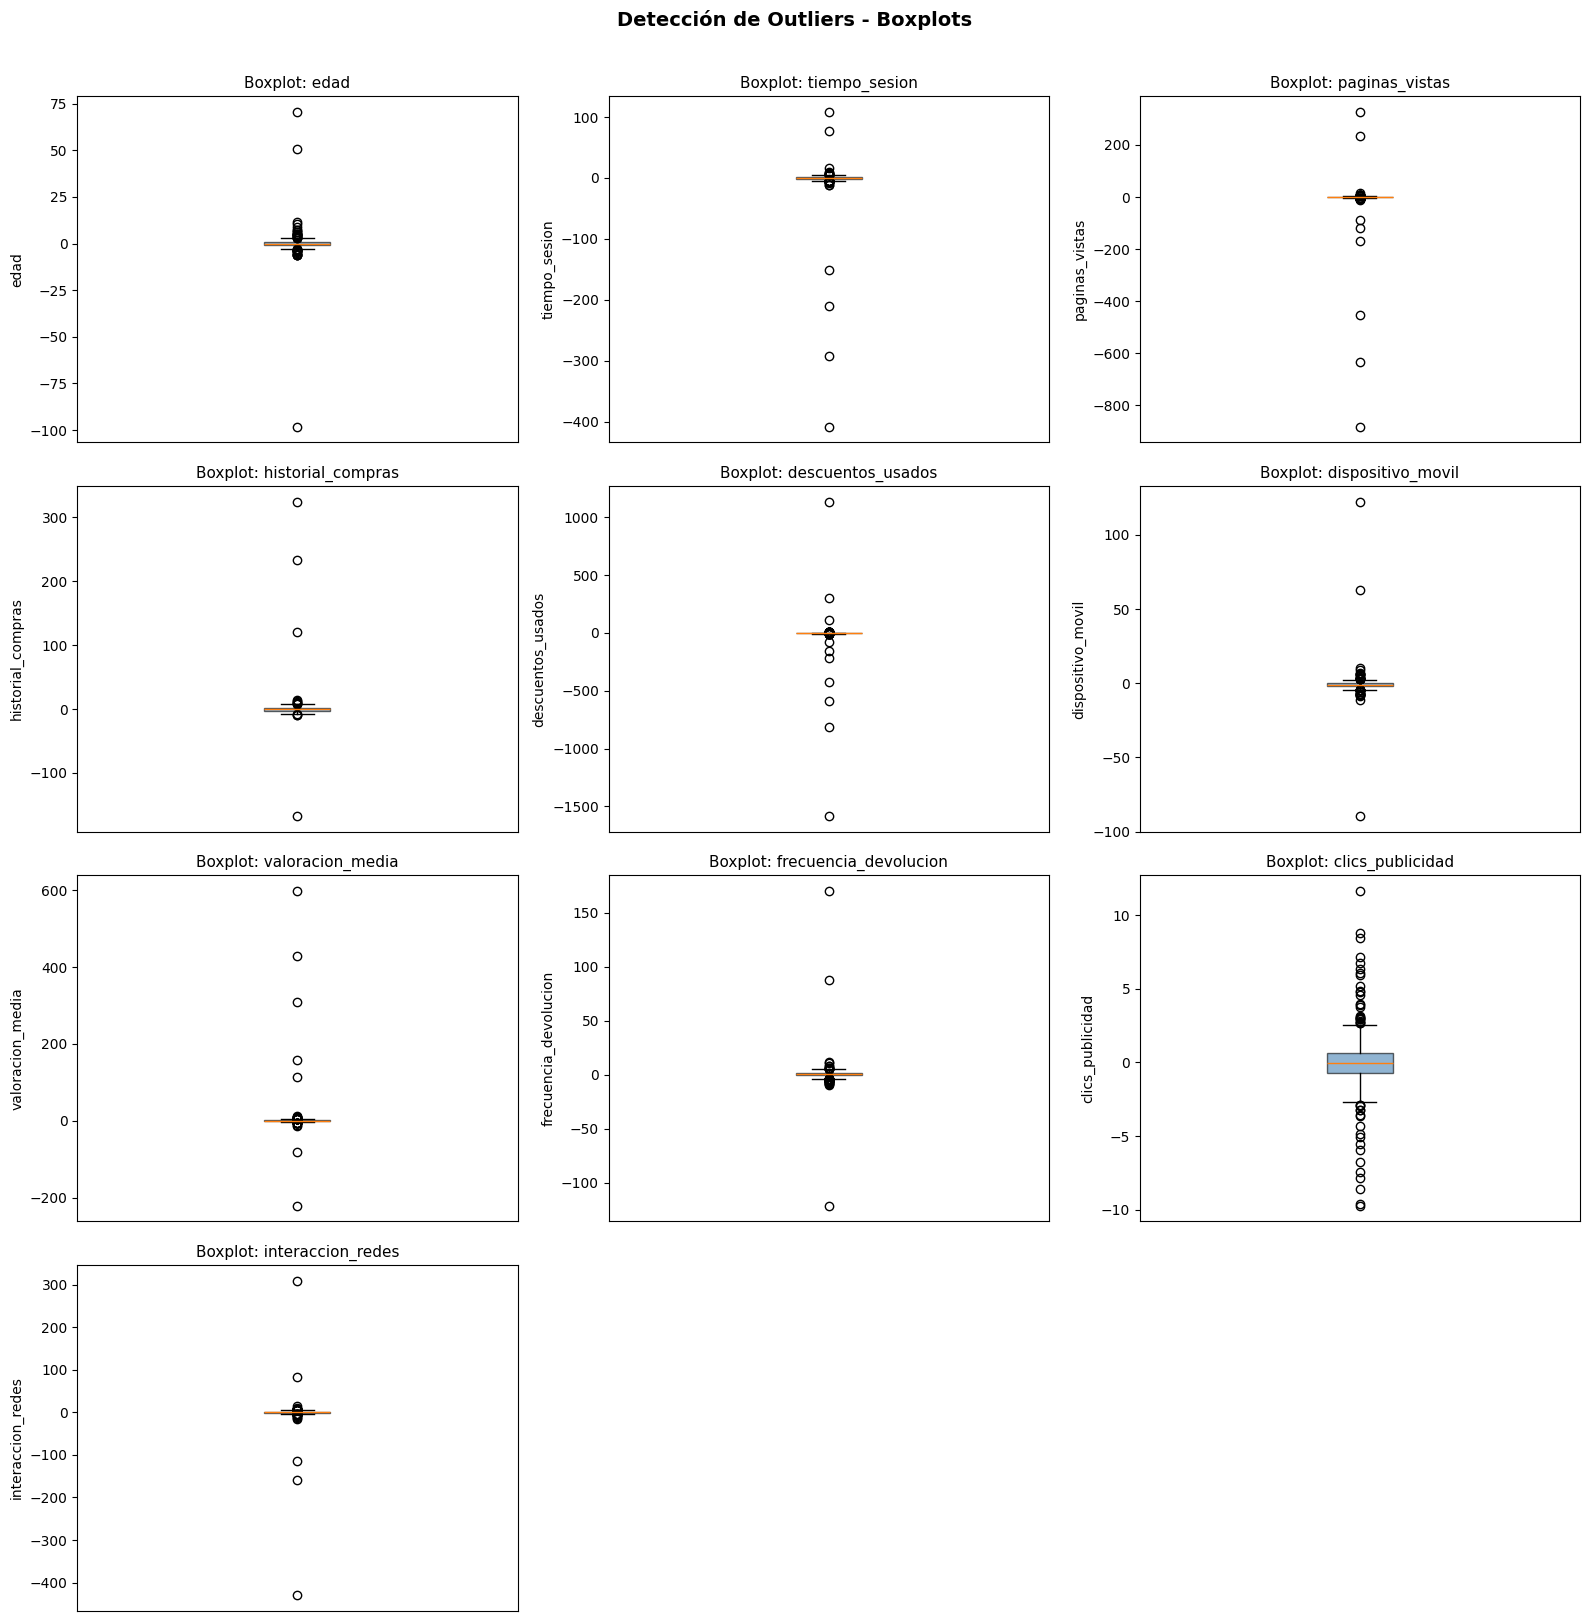

In [34]:
fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(16, 4 * nrows),
    squeeze=False
)

axes = axes.flatten()

for i, col in enumerate(numericas_plot):
    datos = df[col].dropna()

    axes[i].boxplot(
        datos,
        vert=True,
        patch_artist=True,
        boxprops=dict(facecolor='steelblue', alpha=0.6)
    )

    axes[i].set_title(f'Boxplot: {col}', fontsize=11)
    axes[i].set_ylabel(col)
    axes[i].set_xticks([])

# Ocultar los subgráficos sobrantes
for j in range(n, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(
    'Detección de Outliers - Boxplots',
    fontsize=14,
    fontweight='bold',
    y=1.01
)

plt.tight_layout()
plt.show()

### Interpretación de la exploración

- Confirma las dimensiones y los tipos de datos que aparecen al ejecutar las celdas anteriores.
- la exploracion nos permitio encontrar valores atipicos y nulos.
- Los histogramas y boxplots permiten identificar distribuciones asimétricas y posibles valores extremos. Un valor extremo no es automáticamente un error, por lo que no se elimina una fila sin justificación.

## 3. Tratamiento de valores faltantes y análisis de valores extremos

La imputación por mediana es robusta frente a valores extremos. Se aplica solo a las columnas enumeradas y se comprueba después si quedan nulos. Para evitar alterar la interpretación del conjunto, el análisis de outliers se reporta por separado: la versión principal del modelo conserva las observaciones originales.

In [35]:
# 1. Tratamiento de Nulos
columnas_con_nulos = ['edad', 'tiempo_sesion', 'paginas_vistas','historial_compras',
                      'descuentos_usados','dispositivo_movil','valoracion_media',
                      'frecuencia_devolucion','clics_publicidad','interaccion_redes']
for col in columnas_con_nulos:
    df[col] = df[col].fillna(df[col].median())

print(' Valores nulos por columna:')
print(df.isnull().sum())
df.head(10)

 Valores nulos por columna:
edad                     0
tiempo_sesion            0
paginas_vistas           0
historial_compras        0
descuentos_usados        0
dispositivo_movil        0
valoracion_media         0
frecuencia_devolucion    0
clics_publicidad         0
interaccion_redes        0
interes_tecnologia       0
interes_moda             0
interes_deportes         0
dtype: int64


,edad,tiempo_sesion,paginas_vistas,historial_compras,descuentos_usados,dispositivo_movil,valoracion_media,frecuencia_devolucion,clics_publicidad,interaccion_redes,interes_tecnologia,interes_moda,interes_deportes
0,0.473008,-2.015216,-0.617204,1.912964,1.104647,7.124469,-2.477666,-0.135015,-0.542116,-0.761970,0,1,1
1,0.578279,0.967299,1.443789,0.993972,-0.620909,-0.667771,-1.835993,-4.181187,1.502827,-1.455356,1,0,0
2,0.101556,-0.773922,-0.164761,0.464491,2.402765,-1.150528,0.157838,0.322459,-0.268127,0.219723,1,0,1
3,-0.091381,-1.361323,2.749614,-1.941579,-0.092780,-3.207476,-1.517199,1.829656,0.880481,-0.589325,0,1,0
4,1.953657,1.248484,1.212312,0.515772,-0.559830,-0.907930,113.927263,1.052013,0.281696,0.341631,1,0,1
5,0.172812,0.856929,-0.005832,0.935800,-0.192766,-1.618146,-0.190089,0.334666,-2.119301,0.251942,1,0,0
6,1.632245,-0.332428,-2.016467,2.059156,-1.063919,-0.199774,3.182819,-0.773510,-0.295972,0.355703,0,0,0
7,0.488154,3.182272,0.073469,-1.356166,0.072609,-1.647630,4.485935,1.848041,-0.516048,3.340701,1,1,0
8,0.793226,-2.100986,0.009654,-4.197970,-1.066401,0.668873,2.106573,0.501959,-0.745620,1.535055,0,0,0
9,0.937225,-3.263823,0.891710,-4.372928,-1.348463,-0.759174,0.447149,0.109971,-0.655751,0.269222,0,1,1


In [36]:
# Columnas numéricas continuas que quieres analizar
columnas_continuas = [
    'edad',
    'tiempo_sesion',
    'paginas_vistas',
    'historial_compras',
    'descuentos_usados',
    'valoracion_media',
    'frecuencia_devolucion',
    'clics_publicidad',
    'interaccion_redes'
]

# Calcular los límites IQR por columna
resultados = []

for col in columnas_continuas:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    mascara = (
        (df[col] < limite_inferior) |
        (df[col] > limite_superior)
    )

    resultados.append({
        'columna': col,
        'Q1': Q1,
        'Q3': Q3,
        'limite_inferior': limite_inferior,
        'limite_superior': limite_superior,
        'cantidad_outliers': int(mascara.sum()),
        'porcentaje_outliers': mascara.mean() * 100
    })

tabla_outliers = pd.DataFrame(resultados)

print(tabla_outliers.round(3))


                 columna     Q1     Q3  limite_inferior  limite_superior  \
0                   edad -0.663  0.688           -2.690            2.716   
1          tiempo_sesion -1.201  0.915           -4.375            4.090   
2         paginas_vistas -1.111  1.250           -4.652            4.791   
3      historial_compras -2.283  1.361           -7.749            6.826   
4      descuentos_usados -1.684  0.374           -4.769            3.459   
5       valoracion_media -1.143  1.008           -4.371            4.236   
6  frecuencia_devolucion -0.540  1.574           -3.710            4.745   
7       clics_publicidad -0.652  0.595           -2.524            2.467   
8      interaccion_redes -0.657  1.420           -3.772            4.536   

   cantidad_outliers  porcentaje_outliers  
0                 49                1.842  
1                 45                1.692  
2                 45                1.692  
3                 17                0.639  
4                 6

In [37]:
mascara_outliers = pd.Series(False, index=df.index)

for col in columnas_continuas:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    mascara_columna = (
        (df[col] < limite_inferior) |
        (df[col] > limite_superior)
    )

    mascara_outliers |= mascara_columna

filas_outliers = df.loc[mascara_outliers]

print("Total de filas:", len(df))
print("Filas con al menos un outlier:", len(filas_outliers))
print(
    "Porcentaje de filas afectadas:",
    round(mascara_outliers.mean() * 100, 2), "%"
)

display(filas_outliers)


Total de filas: 2660
Filas con al menos un outlier: 405
Porcentaje de filas afectadas: 15.23 %


,edad,tiempo_sesion,paginas_vistas,historial_compras,descuentos_usados,dispositivo_movil,valoracion_media,frecuencia_devolucion,clics_publicidad,interaccion_redes,interes_tecnologia,interes_moda,interes_deportes
1,0.578279,0.967299,1.443789,0.993972,-0.620909,-0.667771,-1.835993,-4.181187,1.502827,-1.455356,1,0,0
4,1.953657,1.248484,1.212312,0.515772,-0.559830,-0.907930,113.927263,1.052013,0.281696,0.341631,1,0,1
7,0.488154,3.182272,0.073469,-1.356166,0.072609,-1.647630,4.485935,1.848041,-0.516048,3.340701,1,1,0
16,-1.234645,0.035793,5.547202,-1.625651,1.236459,0.015503,0.318087,1.076502,-0.886238,-0.407085,1,0,0
40,0.658691,0.822016,-2.549229,-0.003009,-4.155995,-0.981453,1.155849,-4.040988,-1.608927,-0.424618,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2615,2.336146,-0.057786,-0.243714,1.072046,8.942765,-1.259433,-0.221220,1.824585,0.357854,1.343289,0,0,0
2628,-6.302314,-0.057786,1.552328,1.127377,1.408353,-0.677207,-2.531774,-0.118014,-1.020740,-2.188426,1,0,1
2636,0.250572,-1.609015,-3.019797,1.557645,-4.538873,1.045672,-2.196564,-5.745838,-0.825271,-2.578981,0,0,0
2652,-0.078490,0.206111,-1.830676,-0.164968,-4.834695,1.399045,-0.111521,-4.196333,-0.048877,-1.376984,0,1,0


**Decisión sobre outliers.** El notebook calcula límites IQR y crea copias recortadas (`X_train_tratado` y `X_test_tratado`) para permitir una prueba posterior. Esas copias no se usan en el modelo principal, de modo que la evaluación principal corresponde a los datos sin recorte.

## 4. Definición de predictores, objetivos y particiones

Se separan los tres objetivos de los predictores y se reserva el 20 % de los datos para la prueba final. La prueba se usa al final para estimar el rendimiento; las decisiones entre configuraciones se toman con validación, no con el conjunto de prueba.

In [38]:
# X contiene las variables continuas; Y contiene las 3 salidas
X = df.drop(columns=[
    'interes_tecnologia',
    'interes_moda',
    'interes_deportes'
])

# y contiene las 3 variables objetivo
y = df[[
    'interes_tecnologia',
    'interes_moda',
    'interes_deportes'
]]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}")
print(f"Dimensiones de y_train: {y_train.shape}")
print(f"Dimensiones de y_test: {y_test.shape}")

# Comprobar distribución de las variables objetivo
print("\nDistribución de las variables objetivo:")
print(y.apply(lambda columna: columna.value_counts()).fillna(0))

Dimensiones de X_train: (2128, 10)
Dimensiones de X_test: (532, 10)
Dimensiones de y_train: (2128, 3)
Dimensiones de y_test: (532, 3)

Distribución de las variables objetivo:
   interes_tecnologia  interes_moda  interes_deportes
0                1504          1497              1507
1                1156          1163              1153


In [39]:
# Separar una porción de X_train para comparar configuraciones con validación.
# X_test/y_test quedan reservados para la evaluación final.
X_train_model, X_val, y_train_model, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=SEED
)

print("Entrenamiento para ajuste:", X_train_model.shape, y_train_model.shape)
print("Validación:", X_val.shape, y_val.shape)
print("Prueba final reservada:", X_test.shape, y_test.shape)


Entrenamiento para ajuste: (1702, 10) (1702, 3)
Validación: (426, 10) (426, 3)
Prueba final reservada: (532, 10) (532, 3)


In [40]:

# Calcular límites IQR únicamente con X_train
limites_iqr = {}

for col in columnas_continuas:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    limites_iqr[col] = (
        Q1 - 1.5 * IQR,
        Q3 + 1.5 * IQR
    )

# Crear copias para conservar los datos originales
X_train_tratado = X_train.copy()
X_test_tratado = X_test.copy()

# Aplicar los mismos límites a entrenamiento y prueba
for col, (inferior, superior) in limites_iqr.items():
    X_train_tratado[col] = X_train_tratado[col].clip(
        lower=inferior,
        upper=superior
    )

    X_test_tratado[col] = X_test_tratado[col].clip(
        lower=inferior,
        upper=superior
    )

# Comprobar dimensiones
print("X_train original:", X_train.shape)
print("X_train tratado:", X_train_tratado.shape)
print("X_test original:", X_test.shape)
print("X_test tratado:", X_test_tratado.shape)

X_train original: (2128, 10)
X_train tratado: (2128, 10)
X_test original: (532, 10)
X_test tratado: (532, 10)


## 5. Modelo MLP principal

La arquitectura tiene capas ocultas de 64, 32 y 16 neuronas con activación ReLU. Dropout y regularización L2 ayudan a reducir el sobreajuste. La capa de salida tiene tres neuronas sigmoid, una por cada objetivo; `binary_crossentropy` es adecuada para salidas binarias independientes en un problema multietiqueta.

Se usa Adam como optimizador. `EarlyStopping` restaura los pesos de la época con menor pérdida de validación y `ReduceLROnPlateau` reduce la tasa de aprendizaje si la validación deja de mejorar.

In [41]:
tf.keras.utils.set_random_seed(SEED)

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation="relu", kernel_regularizer=l2(0.001)),
    Dropout(0.3),
    Dense(32, activation="relu", kernel_regularizer=l2(0.001)),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(3, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        Precision(name="precision"),
        Recall(name="recall")
    ]
)
model.summary()


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,363 (13.14 KB)

 Trainable params: 3,363 (13.14 KB)

 Non-trainable params: 0 (0.00 B)

In [42]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-5,
    verbose=1
)

history = model.fit(
    X_train, y_train,
    epochs=60,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)
print("Entrenamiento completado.")


Epoch 1/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5576 - loss: 0.9138 - precision: 0.4862 - recall: 0.4248 - val_accuracy: 0.6127 - val_loss: 0.9417 - val_precision: 0.6055 - val_recall: 0.3511 - learning_rate: 0.0010
Epoch 2/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5883 - loss: 0.8209 - precision: 0.5317 - recall: 0.3953 - val_accuracy: 0.6260 - val_loss: 0.9150 - val_precision: 0.6138 - val_recall: 0.4113 - learning_rate: 0.0010
Epoch 3/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6011 - loss: 0.8029 - precision: 0.5467 - recall: 0.4483 - val_accuracy: 0.6197 - val_loss: 0.9210 - val_precision: 0.5894 - val_recall: 0.4557 - learning_rate: 0.0010
Epoch 4/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6167 - loss: 0.7585 - precision: 0.5685 - recall: 0.4683 - val_accuracy: 0.6330 - val_loss: 0.9044 - val_precision: 0.6316 - val_recall: 0.4043 - learning_rate: 0.0010
Epoch 5/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6289 - 

### Curvas de aprendizaje

La comparación entre entrenamiento y validación permite detectar señales de sobreajuste. Si la pérdida de entrenamiento sigue bajando mientras la pérdida de validación aumenta, el modelo puede estar aprendiendo detalles que no generalizan. La época seleccionada por `EarlyStopping` se basa en `val_loss`.

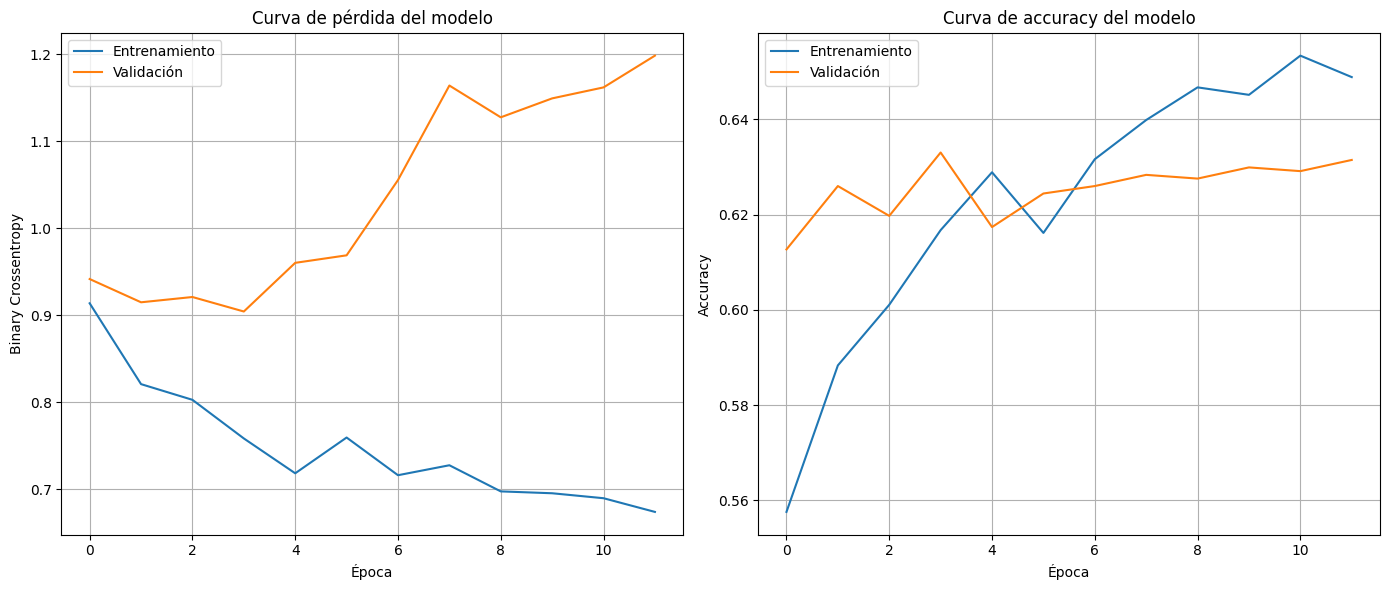

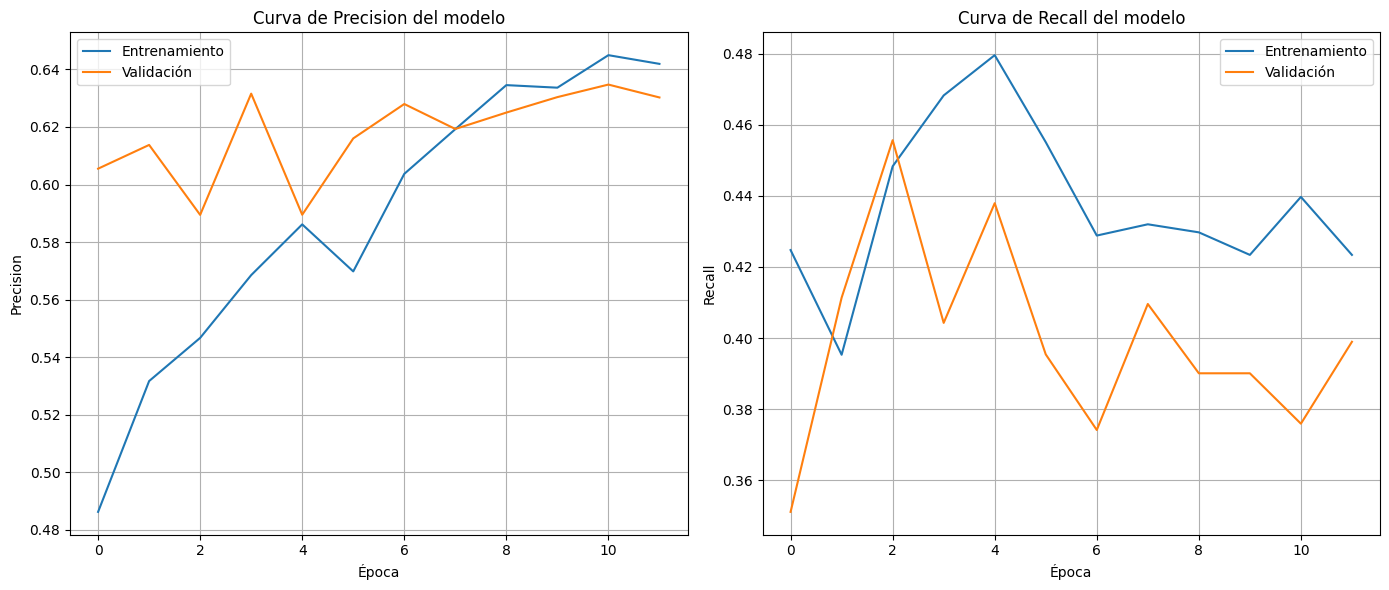

Visualización del historial de entrenamiento completada.
Mejor época: 4
Menor pérdida de validación: 0.9044


In [43]:
# 1. Graficar pérdida y accuracy
plt.figure(figsize=(14, 6))

# Curva de pérdida
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Entrenamiento')
plt.plot(history.history['val_loss'], label='Validación')
plt.title('Curva de pérdida del modelo')
plt.xlabel('Época')
plt.ylabel('Binary Crossentropy')
plt.legend()
plt.grid(True)

# Curva de accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Validación')
plt.title('Curva de accuracy del modelo')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# 2. Graficar Precision y Recall
plt.figure(figsize=(14, 6))

# Curva de Precision
plt.subplot(1, 2, 1)
plt.plot(history.history['precision'], label='Entrenamiento')
plt.plot(history.history['val_precision'], label='Validación')
plt.title('Curva de Precision del modelo')
plt.xlabel('Época')
plt.ylabel('Precision')
plt.legend()
plt.grid(True)

# Curva de Recall
plt.subplot(1, 2, 2)
plt.plot(history.history['recall'], label='Entrenamiento')
plt.plot(history.history['val_recall'], label='Validación')
plt.title('Curva de Recall del modelo')
plt.xlabel('Época')
plt.ylabel('Recall')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("Visualización del historial de entrenamiento completada.")

best_epoch = np.argmin(history.history['val_loss']) + 1
best_val_loss = np.min(history.history['val_loss'])

print(f"Mejor época: {best_epoch}")
print(f"Menor pérdida de validación: {best_val_loss:.4f}")


## 6. Evaluación final en el conjunto de prueba

Se utiliza un umbral inicial de 0,5 para convertir las probabilidades sigmoid en etiquetas 0/1. Se informan métricas globales y por objetivo, junto con matrices de confusión. En clasificación multietiqueta, la accuracy binaria de Keras y la accuracy de subconjunto de scikit-learn no significan lo mismo: la primera cuenta aciertos por etiqueta, mientras que la segunda exige acertar las tres etiquetas de una fila.

In [44]:
# Evaluación de Keras en el conjunto de prueba reservado
resultados_keras = model.evaluate(X_test, y_test, verbose=0, return_dict=True)
print("Métricas Keras en prueba:")
for metrica, valor in resultados_keras.items():
    print(f"{metrica}: {valor:.4f}")

y_test_array = y_test.to_numpy().astype(int)
y_pred_prob = model.predict(X_test, verbose=0)
y_pred = (y_pred_prob >= 0.5).astype(int)

accuracy_subconjunto = accuracy_score(y_test_array, y_pred)
precision_micro = precision_score(y_test_array, y_pred, average="micro", zero_division=0)
recall_micro = recall_score(y_test_array, y_pred, average="micro", zero_division=0)
f1_micro = f1_score(y_test_array, y_pred, average="micro", zero_division=0)
f1_macro = f1_score(y_test_array, y_pred, average="macro", zero_division=0)
hamming = hamming_loss(y_test_array, y_pred)

resumen_final = pd.DataFrame({
    "Métrica": [
        "Binary accuracy (Keras)",
        "Accuracy de subconjunto",
        "Precision micro",
        "Recall micro",
        "F1-score micro",
        "F1-score macro",
        "Hamming loss",
        "Binary cross-entropy (Keras)"
    ],
    "Valor": [
        resultados_keras.get("accuracy", np.nan),
        accuracy_subconjunto,
        precision_micro, recall_micro, f1_micro, f1_macro,
        hamming, resultados_keras.get("loss", np.nan)
    ]
})
display(resumen_final.round(4))

nombres_objetivos = ["Tecnología", "Moda", "Deportes"]
precision_cat, recall_cat, f1_cat, soporte_cat = precision_recall_fscore_support(
    y_test_array, y_pred, average=None, zero_division=0
)
tabla_categoria = pd.DataFrame({
    "Categoría": nombres_objetivos,
    "Precision": precision_cat,
    "Recall": recall_cat,
    "F1-score": f1_cat,
    "Positivos reales": y_test_array.sum(axis=0).astype(int),
    "Positivos predichos": y_pred.sum(axis=0).astype(int)
})
display(tabla_categoria.round(4))

print(classification_report(
    y_test_array, y_pred,
    target_names=nombres_objetivos,
    zero_division=0
))


Métricas Keras en prueba:
accuracy: 0.6341
loss: 0.6873
precision: 0.6272
recall: 0.4145


,Métrica,Valor
0,Binary accuracy (Keras),0.6341
1,Accuracy de subconjunto,0.2406
2,Precision micro,0.6272
3,Recall micro,0.4145
4,F1-score micro,0.4991
5,F1-score macro,0.4671
6,Hamming loss,0.3659
7,Binary cross-entropy (Keras),0.6873


,Categoría,Precision,Recall,F1-score,Positivos reales,Positivos predichos
0,Tecnología,0.8416,0.7750,0.8069,240,221
1,Moda,0.4608,0.2070,0.2857,227,102
2,Deportes,0.4113,0.2468,0.3085,235,141


              precision    recall  f1-score   support

  Tecnología       0.84      0.78      0.81       240
        Moda       0.46      0.21      0.29       227
    Deportes       0.41      0.25      0.31       235

   micro avg       0.63      0.41      0.50       702
   macro avg       0.57      0.41      0.47       702
weighted avg       0.57      0.41      0.47       702
 samples avg       0.44      0.37      0.38       702



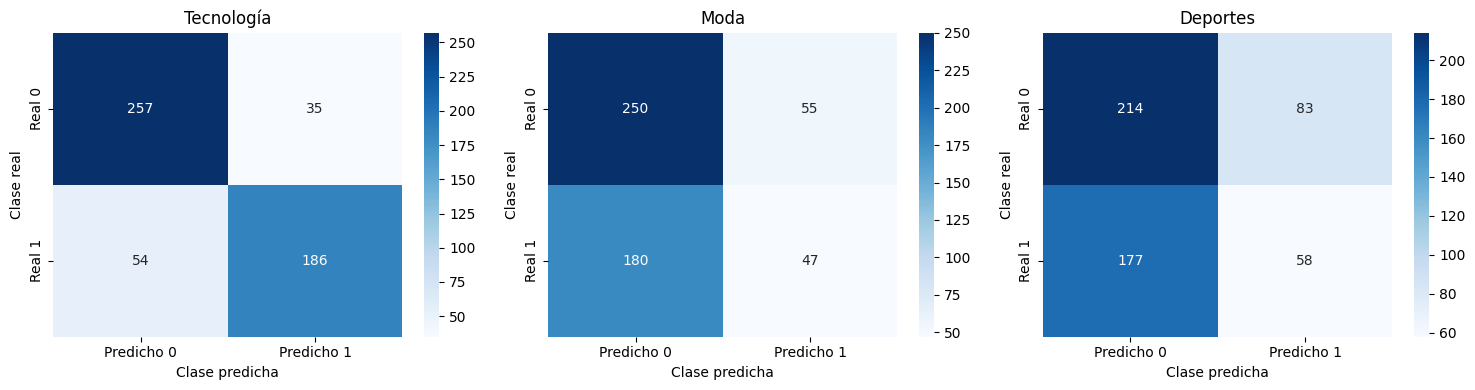

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, nombre in enumerate(nombres_objetivos):
    cm = confusion_matrix(y_test_array[:, i], y_pred[:, i], labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Predicho 0", "Predicho 1"],
        yticklabels=["Real 0", "Real 1"], ax=axes[i]
    )
    axes[i].set_title(nombre)
    axes[i].set_xlabel("Clase predicha")
    axes[i].set_ylabel("Clase real")
plt.tight_layout()
plt.show()


### Interpretación del modelo

El modelo obtuvo una **exactitud binaria del 63,41 %** y una pérdida (*loss*) de **0,6873**. Sin embargo, la exactitud de subconjunto fue de solo **24,06 %**, lo que indica que el modelo logra predecir correctamente todas las categorías de una observación en una proporción reducida de los casos. Además, el *recall micro* de **41,45 %** evidencia dificultades para identificar las etiquetas positivas reales.

Por categoría, **Tecnología** presentó el mejor rendimiento, con un F1-score de **0,8069**, mientras que **Moda** y **Deportes** obtuvieron valores de **0,2857** y **0,3085**, respectivamente. Esto demuestra que el modelo reconoce mejor los patrones asociados a Tecnología, pero tiene dificultades para identificar las otras dos categorías.

En conclusión, se recomienda mejorar la capacidad de detección de las categorías Moda y Deportes mediante el ajuste de los umbrales de clasificación y el análisis de los errores de predicción.

## 7. Comparación controlada de activación y función de pérdida

Para que la comparación sea más justa, se conserva la misma arquitectura general y se cambia una característica por vez. Las configuraciones se comparan sobre el conjunto de validación (`X_val`, `y_val`), no sobre el conjunto de prueba. La pérdida focal se incluye como alternativa experimental; su utilidad debe juzgarse por las métricas de validación, no asumirse de antemano.

In [46]:
def focal_loss(y_true, y_pred):
    gamma = 2.0
    alpha = 0.25
    eps = tf.keras.backend.epsilon()
    y_pred = tf.clip_by_value(y_pred, eps, 1.0 - eps)
    positivos = -alpha * y_true * tf.pow(1.0 - y_pred, gamma) * tf.math.log(y_pred)
    negativos = -(1.0 - alpha) * (1.0 - y_true) * tf.pow(y_pred, gamma) * tf.math.log(1.0 - y_pred)
    return tf.reduce_mean(positivos + negativos)

def crear_modelo_comparacion(activacion="relu", perdida="binary_crossentropy"):
    m = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(64, activation=activacion, kernel_regularizer=l2(0.001)),
        Dropout(0.3),
        Dense(32, activation=activacion, kernel_regularizer=l2(0.001)),
        Dropout(0.2),
        Dense(16, activation=activacion),
        Dense(3, activation="sigmoid")
    ])
    m.compile(optimizer="adam", loss=perdida, metrics=["binary_accuracy"])
    return m

experimentos = [
    {"nombre": "Base: ReLU + BCE", "activacion": "relu", "perdida": "binary_crossentropy"},
    {"nombre": "Tanh + BCE", "activacion": "tanh", "perdida": "binary_crossentropy"},
    {"nombre": "ReLU + focal loss", "activacion": "relu", "perdida": focal_loss}
]

resultados_experimentos = []
for exp in experimentos:
    print("Entrenando:", exp["nombre"])
    tf.keras.utils.set_random_seed(SEED)
    modelo_exp = crear_modelo_comparacion(exp["activacion"], exp["perdida"])
    modelo_exp.fit(
        X_train_model, y_train_model,
        validation_data=(X_val, y_val),
        epochs=60, batch_size=32, verbose=0,
        callbacks=[EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)]
    )
    prob_val = modelo_exp.predict(X_val, verbose=0)
    pred_val = (prob_val >= 0.5).astype(int)
    y_val_array = y_val.to_numpy().astype(int)
    eval_val = modelo_exp.evaluate(X_val, y_val, verbose=0, return_dict=True)
    resultados_experimentos.append({
        "Experimento": exp["nombre"],
        "Binary accuracy validación": eval_val.get("binary_accuracy", np.nan),
        "Precision micro": precision_score(y_val_array, pred_val, average="micro", zero_division=0),
        "Recall micro": recall_score(y_val_array, pred_val, average="micro", zero_division=0),
        "F1 micro": f1_score(y_val_array, pred_val, average="micro", zero_division=0),
        "F1 macro": f1_score(y_val_array, pred_val, average="macro", zero_division=0),
        "Pérdida validación": eval_val["loss"]
    })

tabla_comparativa = pd.DataFrame(resultados_experimentos)
display(tabla_comparativa.sort_values("F1 macro", ascending=False).round(4))


Entrenando: Base: ReLU + BCE
Entrenando: Tanh + BCE
Entrenando: ReLU + focal loss


,Experimento,Binary accuracy validación,Precision micro,Recall micro,F1 micro,F1 macro,Pérdida validación
1,Tanh + BCE,0.6706,0.6542,0.4552,0.5369,0.5042,0.5530
0,Base: ReLU + BCE,0.6620,0.6646,0.3918,0.4930,0.4420,0.6521
2,ReLU + focal loss,0.6651,0.9091,0.2239,0.3593,0.2632,0.0688


### Interpretación

Al comparar los tres experimentos, **Tanh + BCE obtuvo el mejor rendimiento general**, con una exactitud binaria de validación del 67,06 % y un F1-score micro de 0,5369. Además, alcanzó el mayor F1-score macro (0,5042), lo que sugiere un mejor equilibrio en el rendimiento entre las distintas categorías.

El modelo base (**ReLU + BCE**) obtuvo una precisión micro ligeramente superior (0,6646 frente a 0,6542), pero presentó un recall menor (0,3918) y un F1-score micro de 0,4930. Esto indica que, aunque sus predicciones positivas son relativamente precisas, identifica una menor proporción de las etiquetas reales que el modelo con Tanh.

Por otro lado, **ReLU + focal loss** alcanzó una precisión micro muy elevada (0,9091), pero su recall fue de apenas 0,2239 y su F1-score macro de 0,2632. Esto indica que el modelo realiza pocas predicciones positivas y omite muchas etiquetas reales. Aunque su pérdida de validación fue de 0,0688, este valor no debe interpretarse directamente como superior al de los otros experimentos, ya que la focal loss utiliza una función de pérdida diferente de la entropía cruzada binaria (BCE).

En conclusión, **Tanh + BCE es la alternativa más prometedora de las evaluadas**, porque presenta los mejores valores de F1 micro y F1 macro. Se recomienda seleccionarla como candidata para las siguientes pruebas y evaluar sus resultados en el conjunto de prueba antes de considerarla el modelo definitivo.

## 8. Comparación de regularización: Dropout y L2

Se compara una configuración con regularización frente a otra sin Dropout ni L2. Se mantienen las mismas capas y el mismo protocolo de validación. Esta prueba también usa solo validación para comparar; el conjunto de prueba no se vuelve a utilizar para elegir configuración.

,Configuración,Binary accuracy validación,Precision micro,Recall micro,F1 micro,F1 macro,Pérdida validación
1,Sin Dropout ni L2,0.6667,0.6627,0.4179,0.5126,0.4683,0.5751
0,Con Dropout y L2,0.6620,0.6646,0.3918,0.4930,0.4420,0.6521


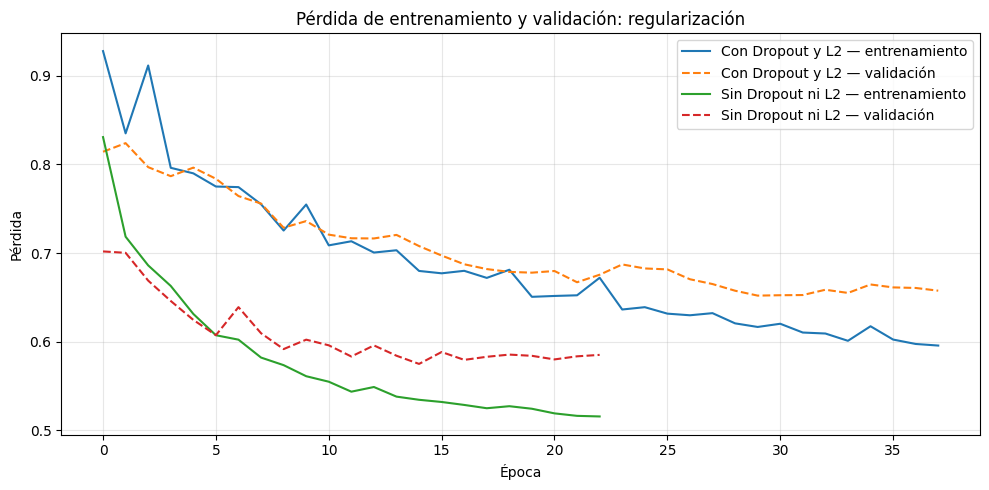

In [47]:
def crear_modelo_regularizacion(usar_regularizacion=True):
    regularizador = l2(0.001) if usar_regularizacion else None
    capas = [Input(shape=(X_train.shape[1],)),
             Dense(64, activation="relu", kernel_regularizer=regularizador)]
    if usar_regularizacion:
        capas.append(Dropout(0.3))
    capas.append(Dense(32, activation="relu", kernel_regularizer=regularizador))
    if usar_regularizacion:
        capas.append(Dropout(0.2))
    capas.extend([Dense(16, activation="relu"), Dense(3, activation="sigmoid")])
    m = Sequential(capas)
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["binary_accuracy"])
    return m

resultados_reg = []
historias_reg = {}
for nombre, usar_reg in [("Con Dropout y L2", True), ("Sin Dropout ni L2", False)]:
    tf.keras.utils.set_random_seed(SEED)
    modelo_exp = crear_modelo_regularizacion(usar_reg)
    historia_exp = modelo_exp.fit(
        X_train_model, y_train_model,
        validation_data=(X_val, y_val),
        epochs=60, batch_size=32, verbose=0,
        callbacks=[EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)]
    )
    prob_val = modelo_exp.predict(X_val, verbose=0)
    pred_val = (prob_val >= 0.5).astype(int)
    y_val_array = y_val.to_numpy().astype(int)
    eval_val = modelo_exp.evaluate(X_val, y_val, verbose=0, return_dict=True)
    resultados_reg.append({
        "Configuración": nombre,
        "Binary accuracy validación": eval_val.get("binary_accuracy", np.nan),
        "Precision micro": precision_score(y_val_array, pred_val, average="micro", zero_division=0),
        "Recall micro": recall_score(y_val_array, pred_val, average="micro", zero_division=0),
        "F1 micro": f1_score(y_val_array, pred_val, average="micro", zero_division=0),
        "F1 macro": f1_score(y_val_array, pred_val, average="macro", zero_division=0),
        "Pérdida validación": eval_val["loss"]
    })
    historias_reg[nombre] = historia_exp

tabla_regularizacion = pd.DataFrame(resultados_reg)
display(tabla_regularizacion.sort_values("F1 macro", ascending=False).round(4))

plt.figure(figsize=(10, 5))
for nombre, historia_exp in historias_reg.items():
    plt.plot(historia_exp.history["loss"], label=f"{nombre} — entrenamiento")
    plt.plot(historia_exp.history["val_loss"], linestyle="--", label=f"{nombre} — validación")
plt.title("Pérdida de entrenamiento y validación: regularización")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 9. Interpretación crítica y conclusiones

Completa esta sección después de ejecutar todas las celdas. Basa la conclusión en las tablas que se generan, sin seleccionar un modelo solo por una métrica.

1. **Rendimiento global:** informa los valores de accuracy binaria, accuracy de subconjunto, precision, recall, F1 micro, F1 macro y Hamming loss.
2. **Rendimiento por categoría:** identifica cuál de los tres intereses tiene mayor y menor F1/recall, y relaciona el resultado con sus falsos negativos y falsos positivos.
3. **Sobreajuste:** compara las curvas de pérdida de entrenamiento y validación y menciona la época con menor pérdida de validación.
4. **Activación y pérdida:** compara la tabla de validación de ReLU/BCE, Tanh/BCE y ReLU/focal loss. Señala qué cambió y cuál fue el criterio de comparación.
5. **Regularización:** compara las dos configuraciones y determina si Dropout/L2 parece ayudar a generalizar en validación.
6. **Limitaciones:** reconoce que el umbral 0,5 es una elección inicial, que el conjunto puede presentar desequilibrio entre etiquetas y que los resultados pueden depender de la partición y de la semilla.

**Criterio de selección sugerido:** prioriza F1 macro si buscas equilibrio entre las tres categorías; revisa precision y recall por separado si los falsos positivos o falsos negativos tienen costes distintos. El conjunto de prueba debe reservarse para la evaluación final del modelo seleccionado.